## **Regresi Linear**
Meminimalkan jumlah kuadrat residual untuk menemukan garis terbaik.

### **Studi Kasus: Insurance Charges**
Feature Selection: Include features like age, bmi, and smoker.

Train Model: Fit a linear regression model.

Evaluate Metrics: Compute MSE, MAE, and R² score.

Visualize Results: Plot predicted vs. actual values.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [24]:
df = pd.read_csv(r'E:\DigitalentDA\Datasets\insurance.csv')

df.head(10)

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,female,27.900,0,yes,southwest,16884.92400
1,1,18,male,33.770,1,no,southeast,1725.55230
2,2,28,male,33.000,3,no,southeast,4449.46200
3,3,33,male,22.705,0,no,northwest,21984.47061
4,4,32,male,28.880,0,no,northwest,3866.85520
5,5,31,female,25.740,0,no,southeast,3756.62160
6,6,46,female,33.440,1,no,southeast,8240.58960
7,7,37,female,27.740,3,no,northwest,7281.50560
8,8,37,male,29.830,2,no,northeast,6406.41070
9,9,60,female,25.840,0,no,northwest,28923.13692


In [25]:
df['smoker'] = df['smoker'].map({
    'yes': 1,
    'no': 0
})

df.head(10)


,index,age,sex,bmi,children,smoker,region,charges
0,0,19,female,27.900,0,1,southwest,16884.92400
1,1,18,male,33.770,1,0,southeast,1725.55230
2,2,28,male,33.000,3,0,southeast,4449.46200
3,3,33,male,22.705,0,0,northwest,21984.47061
4,4,32,male,28.880,0,0,northwest,3866.85520
5,5,31,female,25.740,0,0,southeast,3756.62160
6,6,46,female,33.440,1,0,southeast,8240.58960
7,7,37,female,27.740,3,0,northwest,7281.50560
8,8,37,male,29.830,2,0,northeast,6406.41070
9,9,60,female,25.840,0,0,northwest,28923.13692


In [26]:
df_baru = df.drop(columns=['sex', 'region'])

df_baru.head(10)

,index,age,bmi,children,smoker,charges
0,0,19,27.900,0,1,16884.92400
1,1,18,33.770,1,0,1725.55230
2,2,28,33.000,3,0,4449.46200
3,3,33,22.705,0,0,21984.47061
4,4,32,28.880,0,0,3866.85520
5,5,31,25.740,0,0,3756.62160
6,6,46,33.440,1,0,8240.58960
7,7,37,27.740,3,0,7281.50560
8,8,37,29.830,2,0,6406.41070
9,9,60,25.840,0,0,28923.13692


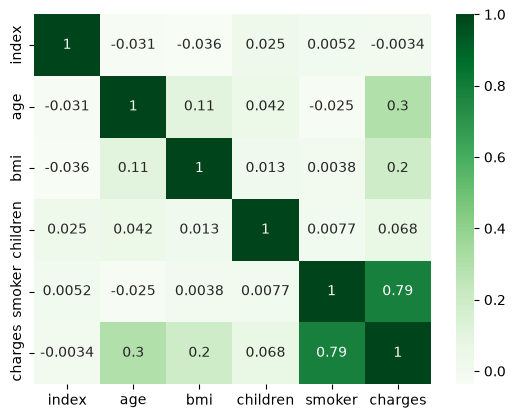

In [27]:
sns.heatmap(df_baru.corr(), annot=True, cmap='Greens')
plt.show()

In [28]:
X = df[['age', 'bmi', 'smoker']]
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 259.41, 326.45,23675.37]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['age','bmi','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.171e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [30]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE: ", mse)
print("MAE: ", mae)
print("R^2: ", r2)

MSE:  34512843.88022789
MAE:  4260.560091099391
R^2:  0.7776932310583375


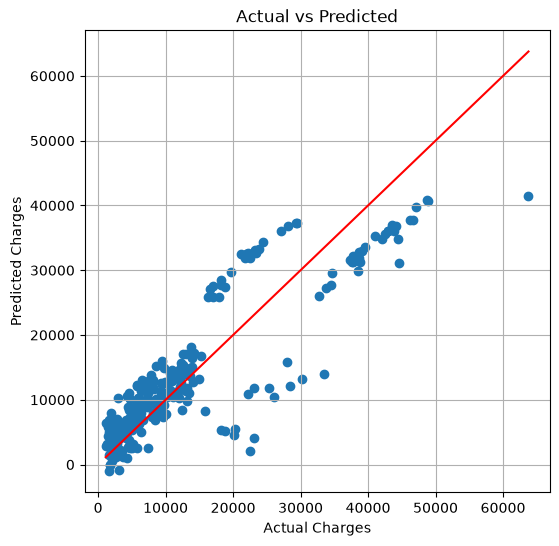

In [38]:
plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")

plt.title("Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.grid(True)

plt.show()